In [11]:
#import camb
import matplotlib.pyplot as plt
import numpy as np
import warnings
import os
import yaml

import numcosmo_II as nc

#from classy import Class
from datetime import datetime
from pathlib import Path
from scipy.special import spherical_jn

## Initial Configurations

In [2]:
current_dir  = Path.cwd()
project_root = current_dir.parent if current_dir.name == 'analysis' else current_dir
yaml_path = project_root / 'config' / "setup.yaml"

print( 100 * "=" )
print( "Loading Initial Setup" )
print( f"Project root set as: {project_root}" )
print( 100 * "=" + "\n" )

with open(yaml_path, "r", encoding = "utf-8" ) as config_file:
    config = yaml.safe_load( config_file )

print(f"{yaml.dump( config, sort_keys = False, allow_unicode = True ) }")

config_out   = config[ "output" ]
output_dir   = project_root / config_out["root"]
os.makedirs(output_dir, exist_ok=True)

timestamp     = datetime.now().strftime( "%Y%m%d_%H%M%S" )
base_filename = f"{config_out[ 'base_name' ]}_{timestamp}"
output_base   = output_dir / base_filename

Loading Initial Setup
Project root set as: /home/usuario/2026_Numerical_Cosmology_I/EP_II

cosmology:
  h: 0.6737
  Omega_b: 0.0493
  Omega_cdm: 0.2657
  Omega_m: 0.315
  Omega_r: 0.0
  Omega_lambda: 0.685
  w0_fld: -1.0
  wa_fld: 0.0
primordial:
  A_s: 2.1e-09
  n_s: 0.9649
  k_pivot: 0.05
growth:
  a_i: 0.0001
  a_f: 1.0
  num_points: 400
  solver:
    rtol: 1.0e-08
    atol: 1.0e-10
spt:
  box_size_L: 500.0
  grid_Ng: 128
  scale_factor_aref: 1.0
  pk_num_bins: 20
  bispectrum_num_bins: 12
  skewness:
    R_min: 4.0
    R_max: 12.0
    num_radii: 9
ensemble:
  num_realizations: 25
  seed_start: 12345
lpt:
  box_size_L: 200.0
  grid_Ng: 128
  scale_factor_aref: 1.0
  a_ini: 0.01
  a_target: 1.0
  seed: 42
  assignment_scheme: ngp
  pk_num_bins: 25
spherical_collapse:
  ai: 0.0001
  z_c: 0.0
  delta_i: 1e-4
  delta_stop: 1.0e4
  default_model: C
  f_i: 1.0
  n_points: 1000
  shooting:
    delta_i_min: 1.0e-08
    delta_i_max: 0.1
    tol: 1.0e-10
    max_iter: 100
boltzmann:
  default

In [3]:
# _____ Cosmological Models & Parameters _____ #

cosmo_params = config[ "cosmology" ]
flrw_keys    = [ "h", "Omega_m", "Omega_r", "Omega_lambda", "w0_fld", "wa_fld" ]
flrw_params  = { k: cosmo_params[ k ] for k in flrw_keys if k in cosmo_params }

lcdm_model = nc.FLRW( **flrw_params )

eds_params = flrw_params.copy()
eds_params.update( {"Omega_m": 1.0, "Omega_lambda": 0.0, "Omega_r": 0.0} )
eds_model  = nc.FLRW( **eds_params )

ocdm_params = flrw_params.copy()
ocdm_params.update( {"Omega_m": flrw_params[ "Omega_m" ], "Omega_lambda": 0.0, "Omega_r": 0.0} )
ocdm_model  = nc.FLRW( **ocdm_params )

# _____ Primordial Spectrum Configuration _____ #

primordial_cfg = config[ "primordial" ]
A_s            = primordial_cfg[ "A_s" ]
n_s            = primordial_cfg[ "n_s" ]
k_pivot        = primordial_cfg[ "k_pivot" ]

In [4]:
# _____ Linear Growth Parameters _____ #

a_i = config[ "growth" ][ "a_i" ]
a_f = config[ "growth" ][ "a_f" ]

N_span = [ np.log( a_i ), np.log( a_f ) ]
N_eval = np.linspace( N_span[0], N_span[ 1 ], config[ "growth" ][ "num_points" ] )
a_eval = np.exp (N_eval )

growth_solver_opts = config[ "growth" ][ "solver" ]

# _____ SPT Field & Ensemble Configurations _____ #

spt_cfg = config[ "spt" ]
gf = nc.GaussianField(
    L    = spt_cfg[ "box_size_L" ],
    Ng   = spt_cfg[ "grid_Ng" ],
    aref = spt_cfg[ "scale_factor_aref" ]
)

spt       = nc.SPTStatistics(gf)
ensem_cfg = config[ "ensemble" ]


In [5]:
# _____ LPT / Zel'dovich Configurations _____ #

lpt_cfg        = config[ "lpt" ]
lpt_L          = float( lpt_cfg[ "box_size_L" ] )
lpt_Ng         = int( lpt_cfg[ "grid_Ng" ] )
lpt_aref       = float( lpt_cfg[ "scale_factor_aref" ] )
lpt_a_ini      = float( lpt_cfg[ "a_ini" ] )
lpt_a_target   = float( lpt_cfg[ "a_target" ] )
lpt_seed       = int( lpt_cfg[ "seed" ] )
lpt_assignment = lpt_cfg[ "assignment_scheme" ]
lpt_pk_bins    = int( lpt_cfg[ "pk_num_bins" ] )

lpt_sim = nc.LPT(
    L = lpt_L, Ng = lpt_Ng, aref = lpt_aref, h = flrw_params[ "h" ], Omega_m = flrw_params["Omega_m"],
    Omega_lambda = flrw_params["Omega_lambda"], a_ini = lpt_a_ini, ai = lpt_a_target
        )

In [7]:
# _____ Boltzmann Solver Configurations _____ #

boltzmann_cfg  = config[ "boltzmann" ]
default_solver = boltzmann_cfg[ "default_solver" ]
z_output       = boltzmann_cfg[ "z_output" ]
gauge          = boltzmann_cfg[ "gauge" ]

k_samp_cfg   = boltzmann_cfg[ "k_sampling" ]
k_min        = k_samp_cfg[ "k_min" ]
k_max        = k_samp_cfg[ "k_max" ]
k_num_points = k_samp_cfg[ "num_points" ]

boltzmann_prec_opts = boltzmann_cfg[ "precision_test" ]

# _____ Superhorizon Potential Configuration _____ #

superhorizon_cfg = config[ "superhorizon_potential" ]

y_i                      = superhorizon_cfg[ "y_i" ]
y_f                      = superhorizon_cfg[ "y_f" ]
superhorizon_solver_opts = superhorizon_cfg[ "solver" ]

## Cosmological Analysis and Tests (Ex 1)

### $D(a)$ and $f(a)$ Validation

In [7]:
sol_eds  = eds_model.solve_growth(  N = N_span, y0 = [ a_i, a_i ], **growth_solver_opts)
sol_lcdm = lcdm_model.solve_growth( N = N_span, y0 = [ a_i, a_i ], **growth_solver_opts)
sol_ocdm = ocdm_model.solve_growth( N = N_span, y0 = [ a_i, a_i ], **growth_solver_opts)

In [8]:
D_eds,  f_eds  = eds_model.get_growth_observables(  sol_eds,  N_eval = N_eval )
D_lcdm, f_lcdm = lcdm_model.get_growth_observables( sol_lcdm, N_eval = N_eval )
D_ocdm, f_ocdm = ocdm_model.get_growth_observables( sol_ocdm, N_eval = N_eval )

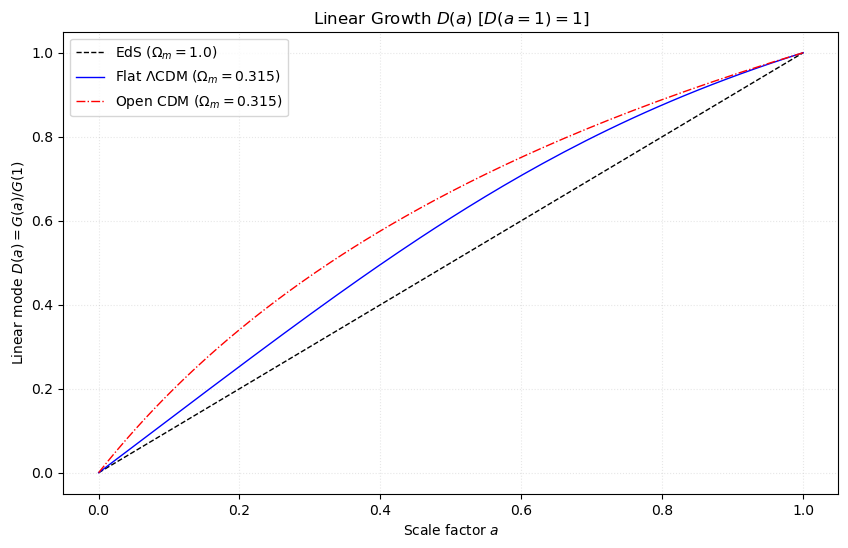

Linear Growth plot saved to: /home/usuario/2026_Numerical_Cosmology_I/EP_II/analysis/output/Test_20261020_222432_linear_growth.png



In [9]:
plt.figure( figsize = ( 10, 6 ) )

plt.plot( a_eval, D_eds,  'k--', lw = 1, label = r'EdS ($\Omega_m=1.0$)' )
plt.plot( a_eval, D_lcdm, 'b-',  lw = 1, label = rf'Flat $\Lambda$CDM ($\Omega_m={lcdm_model.O_matter:.3f}$)' )
plt.plot( a_eval, D_ocdm, 'r-.', lw = 1, label = rf'Open CDM ($\Omega_m={ocdm_model.O_matter:.3f}$)' )

plt.xlabel( r'Scale factor $a$' )
plt.ylabel( r'Linear mode $D(a) = G(a)/G(1)$' )

plt.title( r'Linear Growth $D(a)$ [$D(a=1)=1$]' )

plt.grid( True, ls = ':', alpha = 0.3 )
plt.legend()


linear_growth_path = f"{output_base}_linear_growth.png"
plt.savefig( linear_growth_path, dpi = 300, bbox_inches = "tight" )
#plt.close()
plt.show()
print( f"Linear Growth plot saved to: {linear_growth_path}\n" )

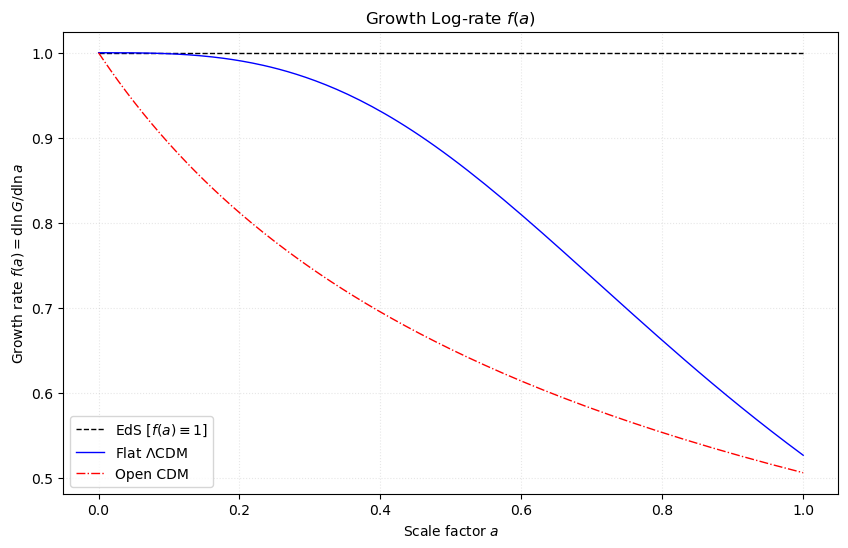

Linear Growth plot saved to: /home/usuario/2026_Numerical_Cosmology_I/EP_II/analysis/output/Test_20261020_222432_growth_rate.png



In [10]:
plt.figure( figsize = ( 10, 6 ) )

plt.plot( a_eval, f_eds,  'k--', lw = 1, label = r'EdS [$f(a) \equiv 1$]' )
plt.plot( a_eval, f_lcdm, 'b-',  lw = 1, label = r'Flat $\Lambda$CDM' )
plt.plot( a_eval, f_ocdm, 'r-.', lw = 1, label = r'Open CDM' )

plt.xlabel( r'Scale factor $a$' )
plt.ylabel( r'Growth rate $f(a) = \mathrm{d}\ln G / \mathrm{d}\ln a$' )

plt.title( r'Growth Log-rate $f(a)$' )

plt.grid( True, ls=':', alpha = 0.3 )
plt.legend()

growth_rate_path = f"{output_base}_growth_rate.png"
plt.savefig( growth_rate_path, dpi = 300, bbox_inches = "tight" )
#plt.close()
plt.show()
print( f"Linear Growth plot saved to: {growth_rate_path}\n" )

In [11]:
print( f"EdS (a=1):  D = {D_eds[-1]:.6f} (expected 1.0) | f = {f_eds[-1]:.6f} (expected 1.0)" )
print( f"LCDM (a=1): D = {D_lcdm[-1]:.6f} | f = {f_lcdm[-1]:.6f}" )
print( f"OCDM (a=1): D = {D_ocdm[-1]:.6f} | f = {f_ocdm[-1]:.6f}" )

EdS (a=1):  D = 1.000000 (expected 1.0) | f = 1.000000 (expected 1.0)
LCDM (a=1): D = 1.000000 | f = 0.527103
OCDM (a=1): D = 1.000000 | f = 0.506548


### Quadrature vs ODE

In [12]:
a_test      = np.linspace( 0.05, 1.0, 25 )
G_ode_vals  = [ sol_lcdm.sol( np.log( a_v ) )[ 0 ] for a_v in a_test ]
G_quad_vals = [ lcdm_model.growth_quadrature( a_v ) for a_v in a_test ]

err_rel = np.abs( np.array( G_ode_vals ) - np.array( G_quad_vals ) ) / np.array( G_quad_vals )
print(f"Maximum relative error: {np.max(err_rel):.3e}")

Maximum relative error: 2.124e-07


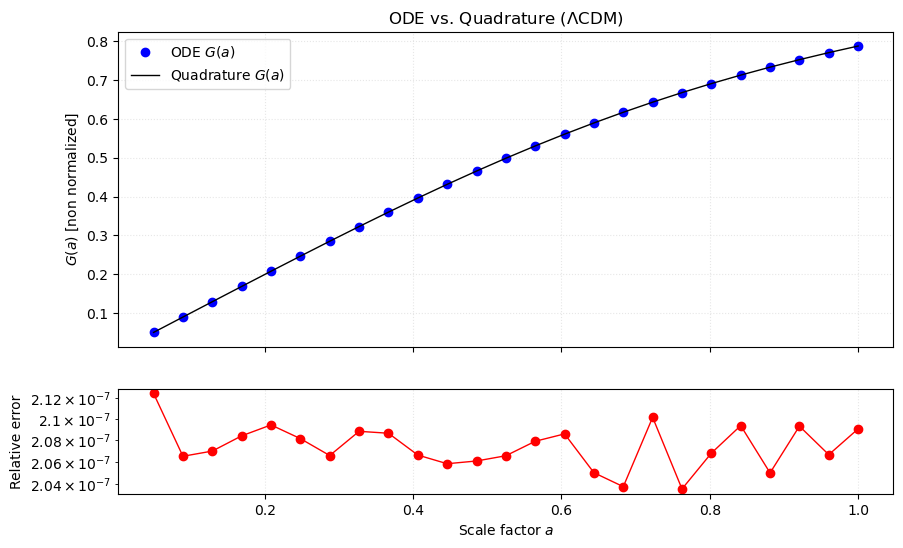

Linear Growth plot saved to: /home/usuario/2026_Numerical_Cosmology_I/EP_II/analysis/output/Test_20261020_222432_quadrature_ODE_validation.png



In [13]:
fig, ( ax1, ax2 ) = plt.subplots( 2, 1, figsize = ( 10, 6 ), sharex = True, gridspec_kw = {'height_ratios': [ 3, 1 ]} )

ax1.plot( a_test, G_ode_vals,  'bo', label = r'ODE $G(a)$' )
ax1.plot( a_test, G_quad_vals, 'k-', lw = 1, label = r'Quadrature $G(a)$' )

ax1.set_ylabel( r'$G(a)$ [non normalized]' )
ax1.set_title( r'ODE vs. Quadrature ($\Lambda\mathrm{CDM}$)' )

ax1.legend()
ax1.grid( True, ls=':', alpha = 0.3)

ax2.plot( a_test, err_rel, 'r-o', lw = 1 )
ax2.set_yscale( 'log' )
ax2.set_xlabel( r'Scale factor $a$' )
ax2.set_ylabel( r'Relative error' )
ax2.grid( True, ls=':', alpha = 0.3 )

quadrature_ODE_validation_path = f"{output_base}_quadrature_ODE_validation.png"
plt.savefig( quadrature_ODE_validation_path, dpi = 300, bbox_inches = "tight" )
#plt.close()
plt.show()
print( f"Linear Growth plot saved to: {quadrature_ODE_validation_path}\n" )

### Initial Conditions Sensibility

In [14]:
a_i_list = [ 1e-3, 1e-4, 1e-5 ]
tol_list = [ ( 1e-6, 1e-8 ), ( 1e-8, 1e-10 ), ( 1e-10, 1e-12 ) ]

print( "=" * 100 )
print( f"{'a_i':<10} | {'rtol, atol':<20} | {'f(a=1)':<14} | {'D(a=1)':<14} | {'Erro Rel. f in a=1':<20}" )
print( "=" * 100 )

f_ref = None

for a_init in a_i_list:
    for rtol, atol in tol_list:
        sol_t = lcdm_model.solve_growth(
            N = [ np.log( a_init ), 0.0 ], y0 = [ a_init, a_init ], rtol = rtol, atol = atol
        )
        D_t, f_t = lcdm_model.get_growth_observables( sol_t, N_eval = [ 0.0 ] )
        
        if f_ref is None:
            f_ref = f_t[ 0 ]
            diff  = 0.0
        else:
            diff = abs( f_t[0] - f_ref ) / f_ref

        print( f"{a_init:<10.1e} | {str((rtol, atol)):<20} | {f_t[0]:<14.8f} | {D_t[0]:<14.8f} | {diff:<20.2e}" )
print("=" * 100)

a_i        | rtol, atol           | f(a=1)         | D(a=1)         | Erro Rel. f in a=1  
1.0e-03    | (1e-06, 1e-08)       | 0.52710275     | 1.00000000     | 0.00e+00            
1.0e-03    | (1e-08, 1e-10)       | 0.52710320     | 1.00000000     | 8.54e-07            
1.0e-03    | (1e-10, 1e-12)       | 0.52710320     | 1.00000000     | 8.62e-07            
1.0e-04    | (1e-06, 1e-08)       | 0.52710281     | 1.00000000     | 1.24e-07            
1.0e-04    | (1e-08, 1e-10)       | 0.52710320     | 1.00000000     | 8.54e-07            
1.0e-04    | (1e-10, 1e-12)       | 0.52710320     | 1.00000000     | 8.62e-07            
1.0e-05    | (1e-06, 1e-08)       | 0.52710276     | 1.00000000     | 2.71e-08            
1.0e-05    | (1e-08, 1e-10)       | 0.52710320     | 1.00000000     | 8.54e-07            
1.0e-05    | (1e-10, 1e-12)       | 0.52710320     | 1.00000000     | 8.62e-07            


## SPT and Mode Coupling (Ex 2)

In [15]:
gf.P_linear = lambda k, a = 1.0: np.where( k == 0, 0.0, 10.0 * ( k / 0.1 ) * np.exp( -( k / 0.8 ) ** 2 ) )

delta_1_x, delta_1_k = gf.Gaussian_field()

delta_2_x, delta_2_k = spt.compute_delta_2( delta_1_k )

delta_tot_k = delta_1_k + delta_2_k
delta_tot_x = delta_1_x + delta_2_x

k_p, P_1, n_modes = spt.spt_power_spectrum( delta_1_k,   num_bins = spt_cfg[ 'pk_num_bins' ] )
_, P_tot, _       = spt.spt_power_spectrum( delta_tot_k, num_bins = spt_cfg[ 'pk_num_bins' ] )

print(f"Linear variance: sigma_1^2 = {np.var(delta_1_x):.4e}")
print(f"Total variance:  sigma_tot^2 = {np.var(delta_tot_x):.4e}")

Linear variance: sigma_1^2 = 4.6023e-01
Total variance:  sigma_tot^2 = 9.1948e-01


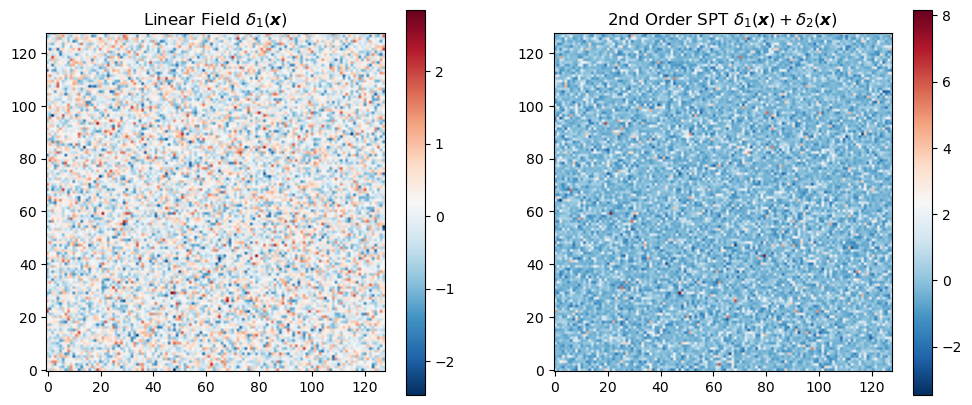

Linear Vs 2nd Order SPT plot saved to: /home/usuario/2026_Numerical_Cosmology_I/EP_II/analysis/output/Test_20261020_222432_Linear_Vs_2ndO_SPT.png



In [16]:
fig = plt.figure( figsize = ( 12, 5 ) )

ax1 = fig.add_subplot( 1, 2, 1 )
im1 = ax1.imshow(delta_1_x[ :, :, 0 ], cmap = 'RdBu_r', origin = 'lower')

ax1.set_title( r'Linear Field $\delta_1(\boldsymbol{x})$' )
plt.colorbar( im1, ax = ax1)

ax2 = fig.add_subplot( 1, 2, 2 )
im2 = ax2.imshow( delta_tot_x[ :, :, 0 ], cmap ='RdBu_r', origin = 'lower' )
ax2.set_title( r'2nd Order SPT $\delta_1(\boldsymbol{x}) + \delta_2(\boldsymbol{x})$' )
plt.colorbar( im2, ax = ax2 )

Linear_Vs_2ndO_SPT_path = f"{output_base}_Linear_Vs_2ndO_SPT.png"
plt.savefig( Linear_Vs_2ndO_SPT_path, dpi = 300, bbox_inches = "tight" )
#plt.close()
plt.show()
print( f"Linear Vs 2nd Order SPT plot saved to: {Linear_Vs_2ndO_SPT_path}\n" )


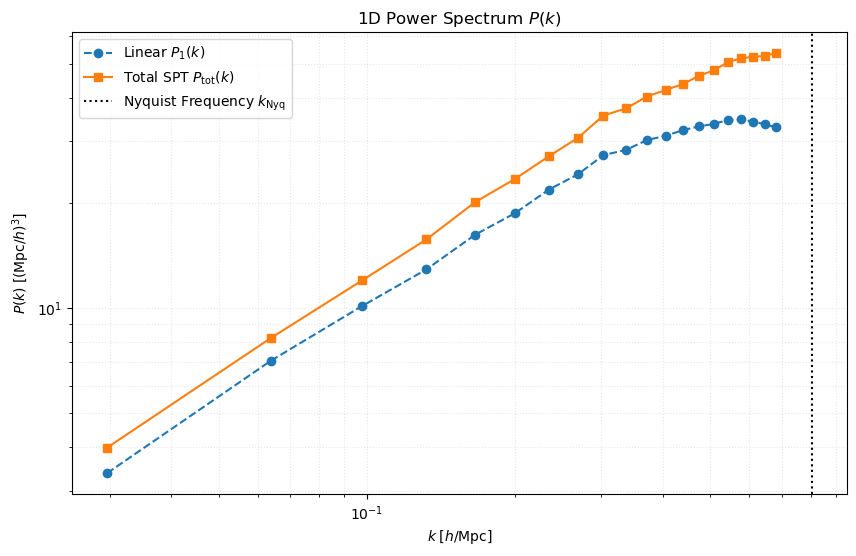

1D Power Spectrum plot saved to: /home/usuario/2026_Numerical_Cosmology_I/EP_II/analysis/output/Test_20261020_222432_Pk_1D_comparison.png



In [17]:
plt.figure( figsize = ( 10, 6 ) )

plt.plot(k_p, P_1,   'o--', label = r'Linear $P_1(k)$' )
plt.plot(k_p, P_tot, 's-',  label = r'Total SPT $P_{\mathrm{tot}}(k)$' )

plt.axvline( np.pi * gf.Ng / gf.L, color='k', ls=':', label = r'Nyquist Frequency $k_{\mathrm{Nyq}}$')
plt.xscale( 'log' )
plt.yscale( 'log' )

plt.xlabel( r'$k \; [h/\mathrm{Mpc}]$' )
plt.ylabel(r'$P(k) \; [(\mathrm{Mpc}/h)^3]$' )

plt.title( r'1D Power Spectrum $P(k)$' )

plt.grid( True, which = "both", ls = ":", alpha = 0.3 )
plt.legend()

Pk_1D_path = f"{output_base}_Pk_1D_comparison.png"
plt.savefig( Pk_1D_path, dpi = 300, bbox_inches = "tight" )
#plt.close()
plt.show()
print( f"1D Power Spectrum plot saved to: {Pk_1D_path}\n" )

In [18]:
gf.P_linear = lambda k, a = 1.0: np.where( k == 0, 0.0, 0.1 * ( k / 0.1 ) * np.exp( - (k / 0.8 ) ** 2 ) )

delta_1_x, delta_1_k = gf.Gaussian_field()
delta_2_x, delta_2_k = spt.compute_delta_2( delta_1_k )

delta_tot_k = delta_1_k + delta_2_k
delta_tot_x = delta_1_x + delta_2_x

print( f"Linear variance sigma_1^2 = {np.var( delta_1_x ):.4e}" )

k_b, B_meas, B_tree = spt.spt_equilateral_bispectrum(
    delta_tot_k, num_bins = spt_cfg[ 'bispectrum_num_bins' ]
)

R_array = np.linspace( 4.0, 12.0, 8 )
_, S3_vals = spt.spt_S3_profile( delta_tot_x, R_array )

Linear variance sigma_1^2 = 4.6023e-03


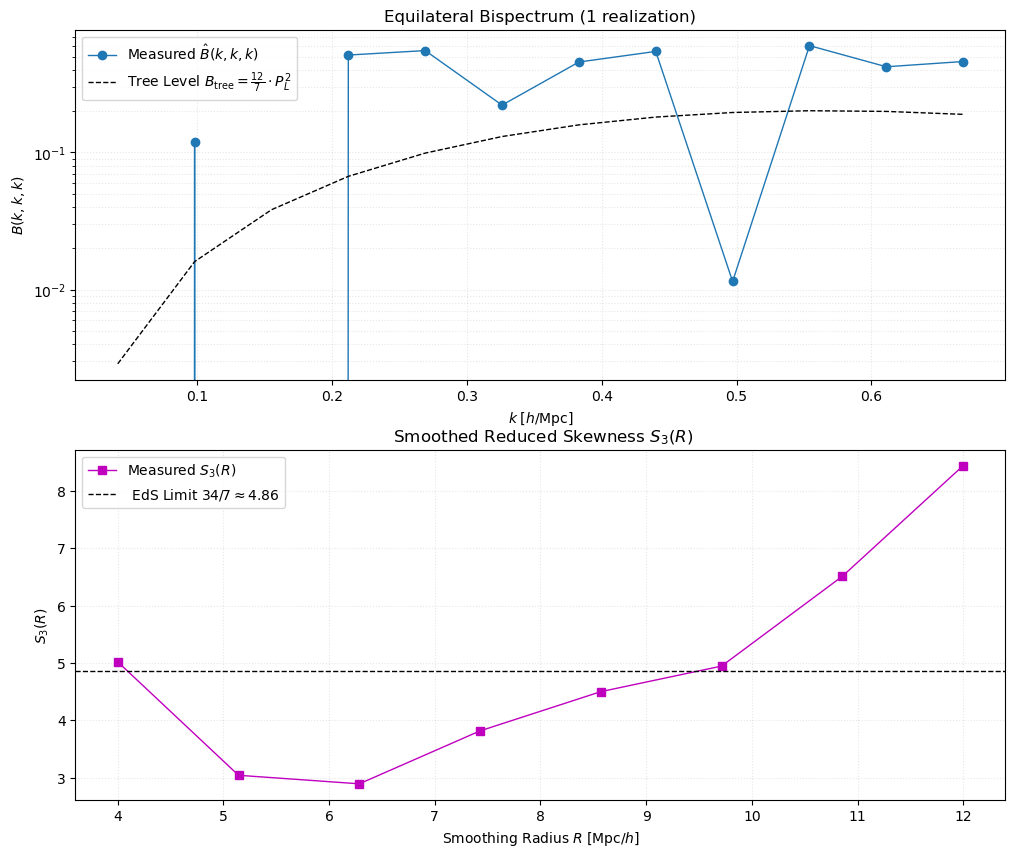

Bispectrum and S_3(R) single realization plot saved to: /home/usuario/2026_Numerical_Cosmology_I/EP_II/analysis/output/Test_20261020_222432_Bispectrum_S3R_1rea.png



In [19]:
fig, axes = plt.subplots(2, 1, figsize=(12, 10))

axes[0].plot( k_b, B_meas, 'o-',  lw = 1, label = r'Measured $\hat{B}(k,k,k)$')
axes[0].plot( k_b, B_tree, 'k--', lw = 1, label = r'Tree Level $B_{\mathrm{tree}} = \frac{12}{7}\cdot P_L^2$')

axes[0].set_yscale( 'log' )
axes[0].set_xlabel( r'$k \; [h/\mathrm{Mpc}]$' )
axes[0].set_ylabel( r'$B(k,k,k)$' )

axes[0].set_title( r'Equilateral Bispectrum (1 realization)' )
axes[0].grid( True, which = "both", ls = ":", alpha = 0.3 )
axes[0].legend()


axes[1].plot( R_array, S3_vals, 's-m', lw=1, label = r'Measured $S_3(R)$' )
axes[1].axhline( 34.0/7.0, color = 'k', linestyle='--', lw = 1, label = r' EdS Limit $34/7 \approx 4.86$' )

axes[1].set_xlabel( r'Smoothing Radius $R \; [\mathrm{Mpc}/h]$' )
axes[1].set_ylabel( r'$S_3(R)$' )
axes[1].set_title( r' Smoothed Reduced Skewness $S_3(R)$')
axes[1].grid( True, ls = ":", alpha = 0.3 )
axes[1].legend()

Bispectrum_S3R_1rea_path = f"{output_base}_Bispectrum_S3R_1rea.png"
plt.savefig( Bispectrum_S3R_1rea_path, dpi = 300, bbox_inches = "tight" )
#plt.close()
plt.show()
print( f"Bispectrum and S_3(R) single realization plot saved to: {Bispectrum_S3R_1rea_path}\n" )


In [ ]:
ensemble_res = spt.run_ensemble_analysis(
    num_realizations = ensem_cfg[ 'num_realizations' ],
    num_bins         = spt_cfg[ 'bispectrum_num_bins' ],
    R_array          = np.linspace( 4.0, 10.0, 7 )
)

In [ ]:
fig, axes = plt.subplots(2, 1, figsize=(12, 10))

axes[0].errorbar(
    ensemble_res[ "k_b" ], ensemble_res[ "B_mean" ], yerr = ensemble_res[ "B_std" ],
    fmt = 'o-', capsize = 5, lw = 1, label = r'Ensemble mean $\langle \hat{B} \rangle$'
)

axes[0].plot(
    ensemble_res[ "k_b" ], ensemble_res["B_tree"], 'k--', lw = 1,
    label = r'Theory $B_{\mathrm{tree}} = \frac{12}{7}P_L^2$'
)

axes[0].set_yscale( 'log' )
axes[0].set_xlabel( r'$k \; [h/\mathrm{Mpc}]$' )
axes[0].set_ylabel( r'$B(k,k,k)$' )
axes[0].set_title(rf'Equilateral Bispectrum ({ensem_cfg["num_realizations"]} Realizations)')
axes[0].grid( True, which = "both", ls = ":", alpha = 0.3 )
axes[0].legend()

axes[1].errorbar(
    ensemble_res[ "R_array" ], ensemble_res[ "S3_mean" ], yerr = ensemble_res[ "S3_std" ],
    fmt = 's-m', capsize = 5, lw = 1, label = r'Ensemble mean $\langle S_3(R) \rangle$'
)
axes[1].axhline( 34.0/7.0, color = 'k', linestyle='--', lw = 1, label = r' EdS Limit $34/7 \approx 4.86$' )

axes[1].set_xlabel( r'Smoothing Radius $R \; [\mathrm{Mpc}/h]$' )
axes[1].set_ylabel( r'$S_3(R)$' )

axes[1].set_title( rf'Smoothed Reduced Skewness $S_3(R)$ ({ensem_cfg[ "num_realizations" ]} Realizações)' )
axes[1].grid( True, ls = ":", alpha = 0.3 )
axes[1].legend()

Bispectrum_S3R_ensemble_path = f"{output_base}_Bispectrum_S3R_ensemble.png"
plt.savefig( Bispectrum_S3R_ensemble_path, dpi = 300, bbox_inches = "tight" )
#plt.close()
plt.show()
print( f"Bispectrum and S_3(R) ensemble realization plot saved to: {Bispectrum_S3R_ensemble_path}\n" )


## LPT & Zel'dovich (Ex 3)

### 1LPT and Mesh Reconstruction

In [6]:
x_p, v_p = lpt_sim.run()

delta_mesh = nc.lpt1.particles_to_mesh_ngp( lpt_sim )

print( "=" * 60 )
print( f"1LPT Simulation Completed:" )
print( f"  Box Length L:           {lpt_sim.L} Mpc/h" )
print( f"  Grid Resolution Ng:     {lpt_sim.Ng}^3 cells ({len(x_p)} particles)" )
print( f"  Linear Growth D1(ai):   {lpt_sim.D1_ai:.5f}" )
print( f"  Growth Rate f1(ai):     {lpt_sim.f1_i:.5f}" )
print( f"  Density min/max/mean:  {delta_mesh.min():.2f} / {delta_mesh.max():.2f} / {delta_mesh.mean():.4f}" )
print( "=" * 60 )

1LPT Simulation Completed:
  Box Length L:           200.0 Mpc/h
  Grid Resolution Ng:     128^3 cells (2097152 particles)
  Linear Growth D1(ai):   1.00000
  Growth Rate f1(ai):     0.52710
  Density min/max/mean:  -1.00 / 49.00 / 0.0000


### 2D Cosmic-Web and Peculiar Velocities

In [7]:
slice_idx = lpt_Ng // 2
cell_size = lpt_L / lpt_Ng

z_min = slice_idx * cell_size
z_max = ( slice_idx + 1 ) * cell_size
in_slice = ( x_p[:, 2] >= z_min ) & ( x_p[ :, 2 ] < z_max )

x_slice = x_p[ in_slice ]
v_slice = v_p[ in_slice ]

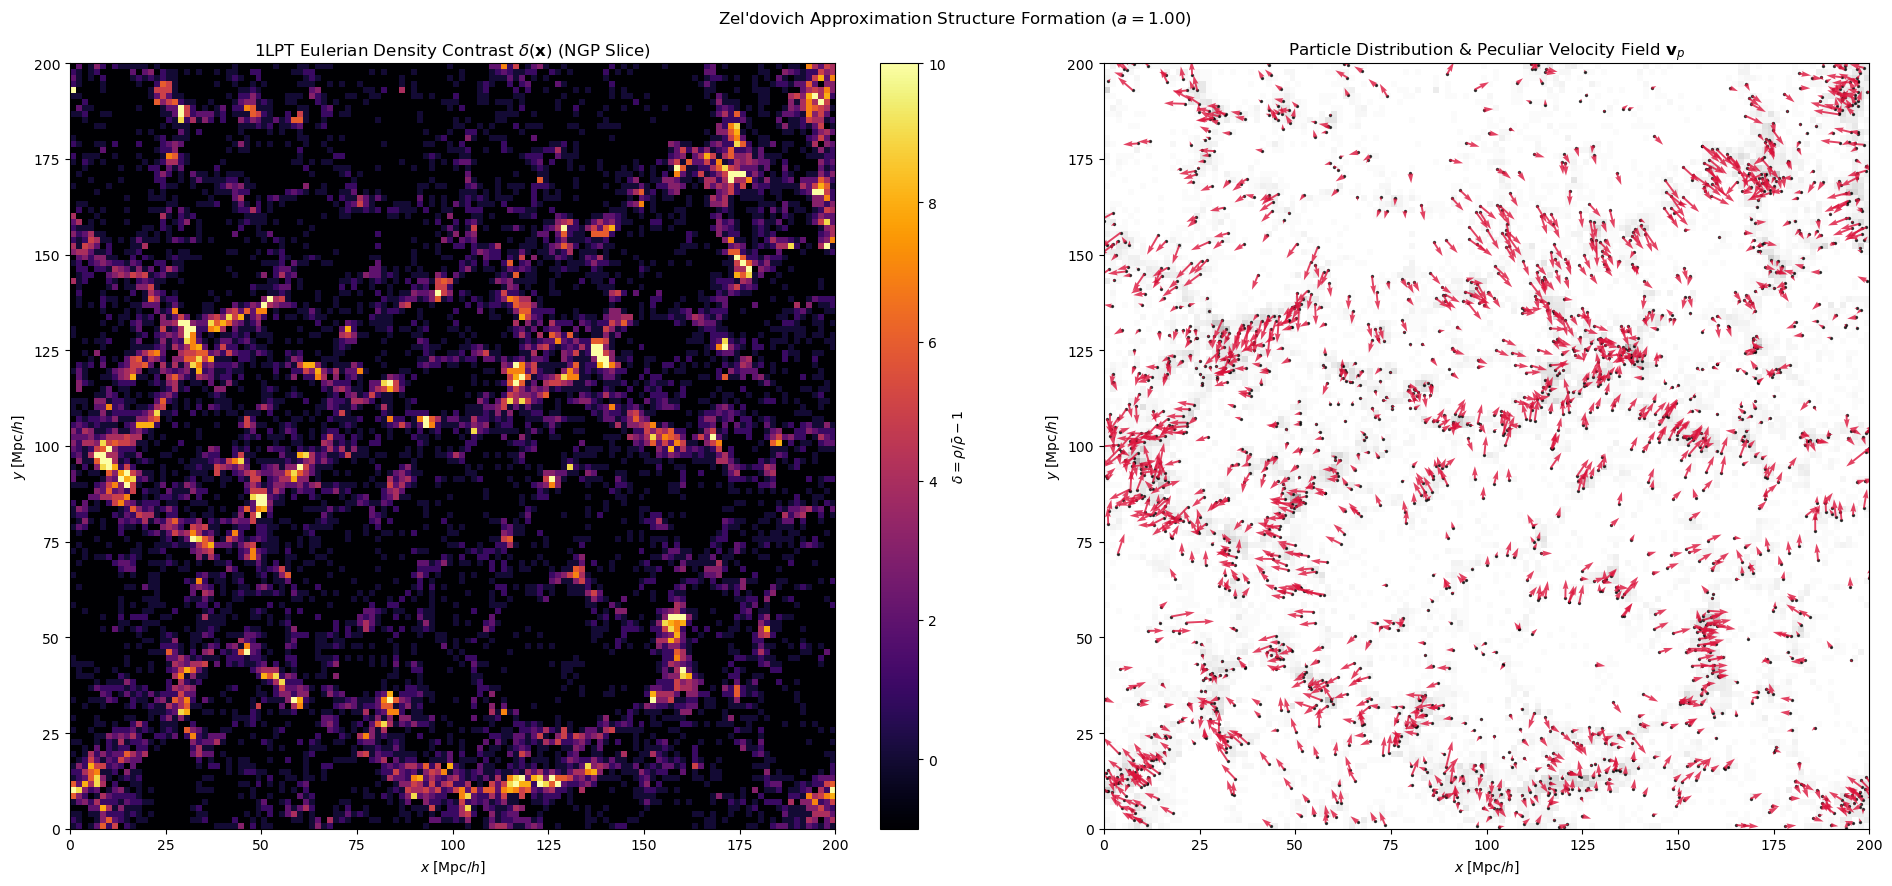

In [9]:
fig, axes = plt.subplots( 1, 2, figsize = ( 20, 9 ) )

im0 = axes[0].imshow(
    delta_mesh[ :, :, slice_idx ].T, origin = "lower", extent = [ 0, lpt_L, 0, lpt_L ],
    cmap = "inferno" , vmin = -1.0 , vmax = np.percentile( delta_mesh, 99.5 )
            )
axes[0].set_title( r"1LPT Eulerian Density Contrast $\delta(\mathbf{x})$ (NGP Slice)" )
axes[0].set_xlabel( r"$x \; [\mathrm{Mpc}/h]$" )
axes[0].set_ylabel( r"$y \; [\mathrm{Mpc}/h]$" )
cbar0 = fig.colorbar( im0, ax = axes[ 0 ], fraction = 0.046 )
cbar0.set_label( r"$\delta = \rho/\bar{\rho} - 1$" )

sub = 8 
axes[1].imshow(
    delta_mesh[ :, :, slice_idx ].T, origin = "lower", 
    extent = [ 0, lpt_L, 0, lpt_L ], cmap = "gray_r", alpha = 0.35
    )

axes[1].scatter(
    x_slice[ ::sub, 0 ], x_slice[ ::sub, 1 ],  s = 2, c = 'black', alpha = 0.7,  label = 'Particles'
    )

v_norm = np.linalg.norm( v_slice, axis = 1 )
v_max  = np.max( v_norm )

arrow_max_length = 10.0  
vx_plot = ( v_slice[ ::sub, 0 ] / v_max ) * arrow_max_length
vy_plot = ( v_slice[ ::sub, 1 ] / v_max ) * arrow_max_length

axes[1].quiver( 
    x_slice[ ::sub, 0 ], x_slice[ ::sub, 1 ],  vx_plot, vy_plot,  color = "crimson",  angles = 'xy', scale_units = 'xy', scale = 1,
    width = 0.0025, headwidth = 3, alpha = 0.8, label = r'Velocidades Peculiares $\mathbf{v}_p$'
        )

axes[1].set_title( r"Particle Distribution & Peculiar Velocity Field $\mathbf{v}_p$" )
axes[1].set_xlabel( r"$x \; [\mathrm{Mpc}/h]$" )
axes[1].set_ylabel( r"$y \; [\mathrm{Mpc}/h]$" )
axes[1].set_xlim( 0, lpt_L )
axes[1].set_ylim( 0, lpt_L )

plt.suptitle( f"Zel'dovich Approximation Structure Formation ($a = {lpt_a_target:.2f}$)", y = 0.98 )
plt.tight_layout()

plot_path_slice = f"{output_base}_lpt_cosmic_web_slice.png"
plt.savefig( plot_path_slice, dpi = 300, bbox_inches = "tight" )
plt.show()

### $P(k)$ and Linear Comparision

In [8]:
k_mesh, p_mesh                  = nc.lpt1.power_spectrum( delta_mesh, lpt_sim )
k_centers, pk_measured, n_modes = nc.lpt1.bin_power_spectrum( k_mesh, p_mesh, nbins = lpt_pk_bins )

P_shot        = ( lpt_L / lpt_Ng ) ** 3  
pk_subtracted = pk_measured - P_shot

pk_lin_ref    = lpt_sim.GF.P_linear( k_centers )
pk_lin_target = ( lpt_sim.D1_ai ** 2 ) * pk_lin_ref

k_nyquist  = np.pi / (lpt_L / lpt_Ng ) 
valid_mask = ( pk_subtracted > 0 ) & ( k_centers <= k_nyquist )

k_plot      = k_centers[ valid_mask ]
pk_plot     = pk_subtracted[ valid_mask ]
pk_lin_plot = pk_lin_target[ valid_mask ]

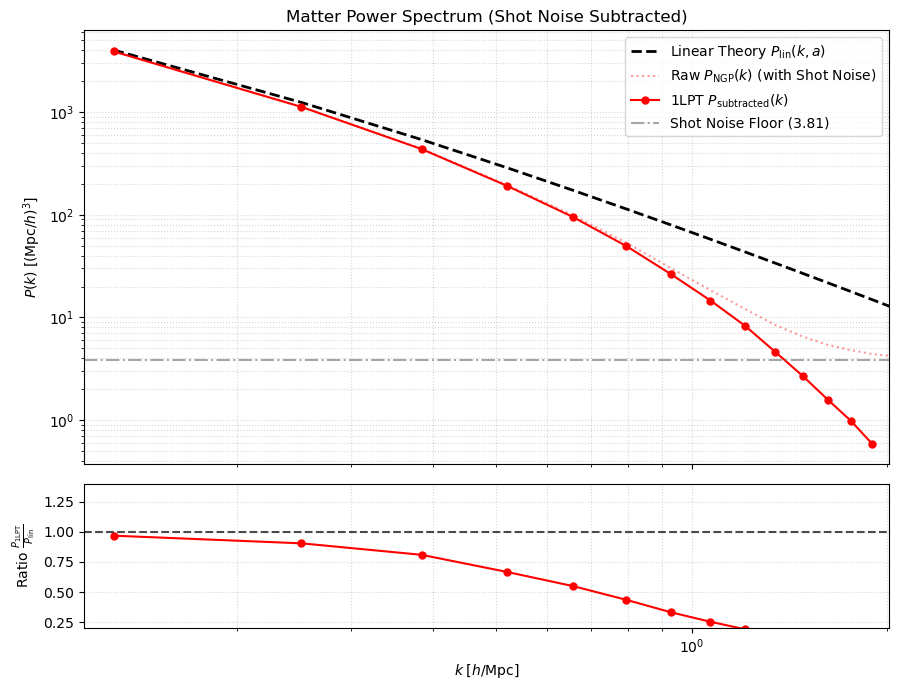

In [11]:
fig, axes = plt.subplots( 2, 1, figsize = (9, 7), sharex = True, gridspec_kw = {"height_ratios": [3, 1]} )

axes[0].plot( k_centers, pk_lin_target, "k--", lw = 2, label = r"Linear Theory $P_{\mathrm{lin}}(k, a)$" )
axes[0].plot( k_centers, pk_measured, "r:", alpha = 0.4, label =r"Raw $P_{\mathrm{NGP}}(k)$ (with Shot Noise)" )
axes[0].plot( k_plot, pk_plot, "r-o", ms = 5, lw = 1.5, label =r"1LPT $P_{\mathrm{subtracted}}(k)$" )
axes[0].axhline( P_shot, color = "gray", linestyle = "-.", alpha = 0.7, label = f"Shot Noise Floor ({P_shot:.2f})" )

axes[0].set_xscale( "log")
axes[0].set_yscale( "log")
axes[0].set_ylabel( r"$P(k) \; [(\mathrm{Mpc}/h)^3]$" )
axes[0].set_title( "Matter Power Spectrum (Shot Noise Subtracted)" )
axes[0].set_xlim( k_centers[0] * 0.9, k_nyquist )
axes[0].grid( True, which = "both", ls = ":", alpha = 0.5 )
axes[0].legend()

ratio = pk_plot / pk_lin_plot
axes[1].plot( k_plot, ratio, "r-o", ms = 5, lw = 1.5 )
axes[1].axhline( 1.0, color = "k", linestyle = "--", alpha = 0.7 )
axes[1].set_xscale( "log" )
axes[1].set_xlabel( r"$k \; [h/\mathrm{Mpc}]$" )
axes[1].set_ylabel( r"Ratio $\frac{P_{\mathrm{1LPT}}}{P_{\mathrm{lin}}}$" )
axes[1].set_ylim( 0.2, 1.4 )
axes[1].grid( True, which = "both", ls = ":", alpha = 0.5 )

plt.tight_layout()

plot_path_pk = f"{output_base}_lpt_power_spectrum.png"
plt.savefig( plot_path_pk, dpi = 300, bbox_inches = "tight" )
plt.show()

In [12]:
# Configuration
L = 200.0
NG_LIST = [64, 128, 256]
N_SEEDS = 10                 # adjust to 5 for Ng=256 if it's too slow

# k bins (log-spaced, same for all resolutions)
K_MIN, K_MAX = 0.03, 3.0
NBINS        = 40
bins_log     = np.logspace(np.log10(K_MIN), np.log10(K_MAX), NBINS + 1)
k_centers    = np.sqrt(bins_log[:-1] * bins_log[1:])

results = {}

for Ng in NG_LIST:
    print(f"\n=== Ng = {Ng} (NGP) ===")
    lpt = nc.lpt1.LPT(L=L, Ng=Ng, aref=1.0, h=0.67,
                          Omega_m=0.315, Omega_lambda=0.685,
                          Omega_r=0.0, w0_fld=-1.0, wa_fld=0.0,
                          a_ini=0.01, ai=1.0)

    P_mesh_all = np.full((N_SEEDS, NBINS), np.nan)

    for i, seed in enumerate(range(N_SEEDS)):
        print(f"  seed {seed+1}/{N_SEEDS} ...", end=" ", flush=True)
        lpt.run(seed=seed)

        #NGP mass assignment 
        delta_mesh = nc.lpt1.particles_to_mesh_ngp(lpt)

        k_m, P_m_m = nc.lpt1.power_spectrum(delta_mesh, lpt)
        P_mesh_bin, _ = nc.lpt1.bin_in_log(P_m_m.ravel(), k_m.ravel(), bins_log)
        P_mesh_all[i] = P_mesh_bin

        print("ok")

        # Averages over seeds
        warnings.filterwarnings("ignore", message="Mean of empty slice", category=RuntimeWarning)
        warnings.filterwarnings("ignore", message="Degrees of freedom <= 0 for slice", category=RuntimeWarning)
        
        P_mesh_avg = np.nanmean(P_mesh_all, axis=0)
        P_mesh_err = np.nanstd(P_mesh_all, axis=0) / np.sqrt(N_SEEDS)

        # Resolution diagnostics
        dx     = lpt.L / Ng
        k_nyq  = np.pi / dx
        P_shot = lpt.GF.V / Ng**3
        N_p    = Ng**3

        # Linear spectrum on the same k grid
        P_lin = lpt.GF.P_linear(k_centers)

        results[Ng] = dict(
            k_centers = k_centers.copy(),
            P_lin     = P_lin.copy(),
            P_mesh    = P_mesh_avg,
            P_mesh_err= P_mesh_err,
            k_nyq     = k_nyq,
            P_shot    = P_shot,
            N_p       = N_p,
            dx        = dx,)


=== Ng = 64 (NGP) ===
okseed 1/10 ... 
  seed 2/10 ... ok
  seed 3/10 ... ok
  seed 4/10 ... ok
  seed 5/10 ... ok
  seed 6/10 ... ok
  seed 7/10 ... ok
  seed 8/10 ... ok
  seed 9/10 ... ok
  seed 10/10 ... ok

=== Ng = 128 (NGP) ===
okseed 1/10 ... 
  seed 2/10 ... ok
  seed 3/10 ... ok
  seed 4/10 ... ok
  seed 5/10 ... ok
  seed 6/10 ... ok
  seed 7/10 ... ok
  seed 8/10 ... ok
  seed 9/10 ... ok
  seed 10/10 ... ok

=== Ng = 256 (NGP) ===
okseed 1/10 ... 
  seed 2/10 ... ok
  seed 3/10 ... ok
  seed 4/10 ... ok
  seed 5/10 ... ok
  seed 6/10 ... ok
  seed 7/10 ... ok
  seed 8/10 ... ok
  seed 9/10 ... ok
  seed 10/10 ... ok


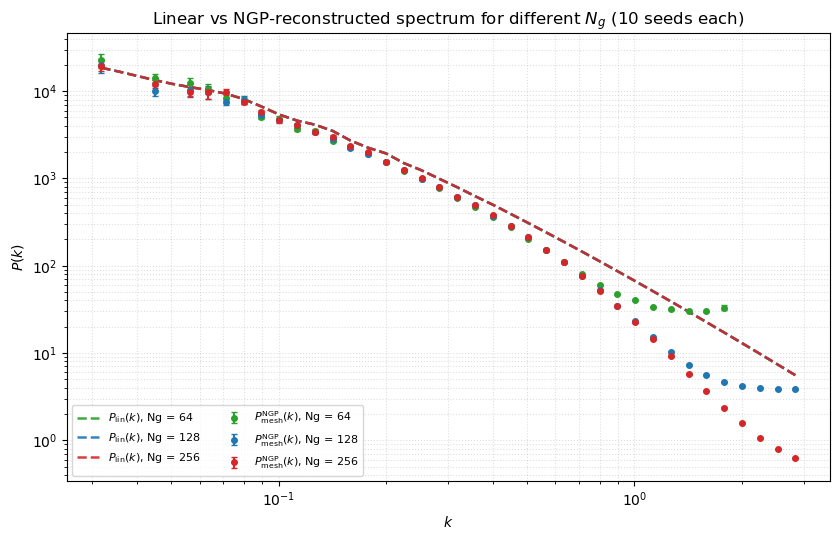


  Ng |        N_p |         dx |    k_Nyq |     P_shot
  64 |     262144 |     3.1250 |    1.005 |    30.5176
 128 |    2097152 |     1.5625 |    2.011 |     3.8147
 256 |   16777216 |     0.7812 |    4.021 |     0.4768


In [13]:
fig, ax = plt.subplots(figsize=(8.5, 5.5))

colors = {64: 'C2', 128: 'C0', 256: 'C3'}

for Ng, r in results.items():
    col = colors[Ng]
    k   = r['k_centers']

    # P_lin: dashed line (same for all, but plotted per Ng for consistency)
    ax.loglog(k, r['P_lin'], '--', color=col, lw=1.8, alpha=0.9,
              label=fr"$P_{{\rm lin}}(k)$, Ng = {Ng}")

    # P_mesh (NGP, ZA): markers with error bars
    ax.errorbar(k, r['P_mesh'], yerr=r['P_mesh_err'],
                fmt='o', ms=4, color=col, capsize=2,
                label=fr"$P_{{\rm mesh}}^{{\rm NGP}}(k)$, Ng = {Ng}")

ax.set_xlabel(r"$k$")
ax.set_ylabel(r"$P(k)$")
ax.set_title(fr"Linear vs NGP-reconstructed spectrum for different $N_g$ ({N_SEEDS} seeds each)")
ax.legend(fontsize=8, ncol=2, loc='lower left')
ax.grid(True, which='both', ls=':', alpha=0.4)

plt.tight_layout()
plt.savefig("output/ngp_multiNg_P_lin_vs_P_mesh.png", dpi=150)
plt.show()

# SUMMARY TABLE 
print("\n" + "=" * 70)
print(f"{'Ng':>4} | {'N_p':>10} | {'dx':>10} | {'k_Nyq':>8} | {'P_shot':>10}")
print("=" * 70)
for Ng, r in results.items():##
    print(f"{Ng:>4} | {r['N_p']:>10d} | {r['dx']:>10.4f} | "
          f"{r['k_nyq']:>8.3f} | {r['P_shot']:>10.4f}")
print("=" * 70)

## 2LPT

In [7]:
# 1. Initial Gaussian density field
delta_1_x = lpt_sim.delta_x
delta_1_k = lpt_sim.delta_ref_k

# Fourier modes
kx, ky, kz, k = lpt_sim.GF.normal_modes(
    lpt_sim.GF.L,
    lpt_sim.GF.V,
    lpt_sim.GF.Ng
)

k2 = k**2
mask = k2 > 0

# First-order potential in Fourier space
phi1_k = np.zeros_like(delta_1_k, dtype=complex)
phi1_k[mask] = -delta_1_k[mask] / k2[mask]

# 2. Initialize LPT2 and calculate the second-order potential
lpt2_sim = nc.lpt2.LPT2(
    L=lpt_L,
    Ng=lpt_Ng,
    aref=lpt_aref,
    h=flrw_params["h"],
    Omega_m=flrw_params["Omega_m"],
    Omega_lambda=flrw_params["Omega_lambda"],
    a_ini=lpt_a_ini,
    ai=lpt_a_target,
    GF=lpt_sim.GF
)

source2_x, source2_k, phi2_k, phi2_x = (lpt2_sim.Second_Order_Potential(phi1_k=phi1_k))


# 3. Calculate the growth factors

# D1 is calculated by the existing LPT growth solver.
D1_target = lpt_sim.D1_ai

D2_target = -(3.0 / 7.0) * D1_target**2

print(f"D1(ai) / D1(aref) = {D1_target:.6g}")
print(f"Approximate D2(ai) = {D2_target:.6g}")


# 4. Construct the 2LPT particle positions
x_p_2lpt = lpt2_sim.particle_positions_2lpt(
    q=lpt_sim.q,
    Psi1_q=lpt_sim.Psi_q,
    D2=D2_target
)


# 5. Measure the ZA density field
x_p_za = lpt_sim.x_p.copy()

delta_za_x = nc.lpt1.particles_to_mesh_ngp(lpt_sim)
delta_za_k = (lpt_sim.GF.V / lpt_sim.GF.Ng**3) * np.fft.fftn(delta_za_x)

# 6. Measure the 2LPT density field
try:
    lpt_sim.x_p = x_p_2lpt

    delta_2lpt_x = nc.lpt1.particles_to_mesh_ngp(lpt_sim)
    delta_2lpt_k = (
        lpt_sim.GF.V / lpt_sim.GF.Ng**3
    ) * np.fft.fftn(delta_2lpt_x)

finally:
    # Restore the original ZA positions.
    lpt_sim.x_p = x_p_za

# 7. Calculate bispectrum and S3 statistics
spt = nc.SPTStatistics(lpt_sim.GF)

R_array = np.linspace(4.0, 12.0, 8)
num_bins = spt_cfg["bispectrum_num_bins"]

gaussian_results = lpt2_sim.measure_statistics(delta_1_x, delta_1_k, num_bins, "Gaussian", R_array)
za_results = lpt2_sim.measure_statistics(delta_za_x, delta_za_k, num_bins, "ZA", R_array)
lpt2_results = lpt2_sim.measure_statistics(delta_2lpt_x, delta_2lpt_k, num_bins, "2LPT", R_array)

all_results = [
    gaussian_results,
    za_results,
    lpt2_results]

D1(ai) / D1(aref) = 1
Approximate D2(ai) = -0.428571


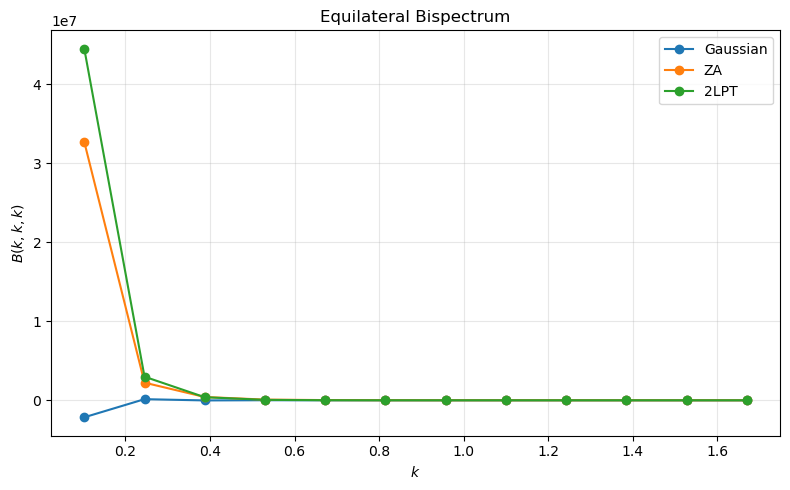

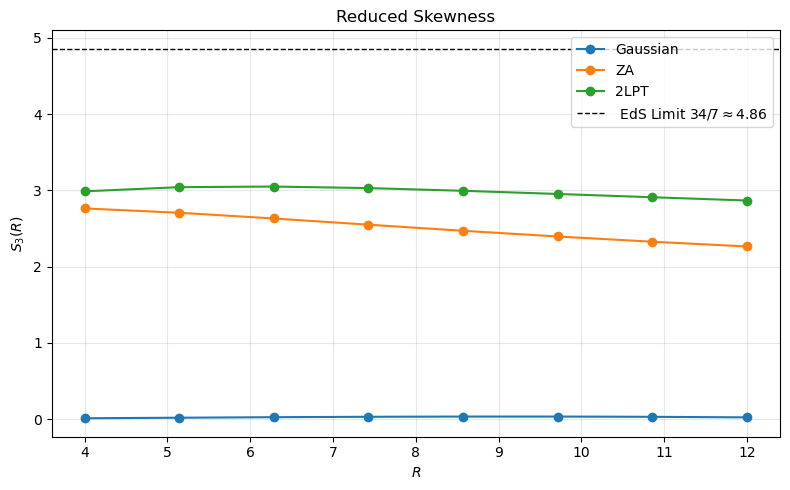

In [8]:
# Equilateral bispectrum comparison.
plt.figure(figsize=(8, 5))

for result in all_results:
    plt.plot(
        result["k_b"],
        result["B_meas"],
        "o-",
        label=result["label"]
    )

plt.xlabel(r"$k$")
plt.ylabel(r"$B(k,k,k)$")
plt.title("Equilateral Bispectrum")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# Reduced skewness comparison.
plt.figure(figsize=(8, 5))

for result in all_results:
    plt.plot(
        R_array,
        result["S3"],
        "o-",
        label=result["label"]
    )

plt.xlabel(r"$R$")
plt.axhline( 34.0/7.0, color = 'k', linestyle='--', lw = 1, label = r' EdS Limit $34/7 \approx 4.86$' )

plt.ylabel(r"$S_3(R)$")
plt.title("Reduced Skewness")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

## Bolztmann Solvers (Ex 5)

### Matter Power Spectrum Reconstruction (CLASS)

In [28]:
h         = cosmo_params[ "h" ]
Omega_b   = cosmo_params[ "Omega_b" ]
Omega_cdm = cosmo_params[ "Omega_cdm" ]
Omega_m   = cosmo_params[ "Omega_m" ]

In [29]:
validator = nc.boltzmann_map.BoltzmannMapValidator(
    fiducial_params = {
    'h': h, 'omega_b': Omega_b * ( h ** 2 ), 'omega_cdm': Omega_cdm * ( h ** 2 ), 'A_s': A_s, 'n_s': n_s, 'k_pivot': k_pivot, 'z': z_output 
    })

cosmo = Class()
cosmo.set(
    {'h': h, 'omega_b': Omega_b * ( h ** 2 ), 'omega_cdm': Omega_cdm * ( h ** 2 ), 'A_s': A_s, 'n_s': n_s, 'k_pivot': k_pivot,
    'output': 'mPk, mTk', 'z_pk': z_output, 'gauge': gauge, 'P_k_max_h/Mpc': k_max, 'non linear': 'none'
    })

cosmo.compute()

In [30]:
k_h   = np.logspace( np.log10( k_min ), np.log10( k_max ), k_num_points ) 
k_mpc = k_h * h                                                   

pk_class_mpc = np.array( [ cosmo.pk_lin( k_val, z_output ) for k_val in k_mpc ] )
pk_class_h   = pk_class_mpc * ( h ** 3 )                                         


tk_dict = cosmo.get_transfer( z_output )
k_tk    = tk_dict[ 'k (h/Mpc)' ] 

if 'd_m' in tk_dict:
    T_m_raw = tk_dict[ 'd_m' ]
else:
    T_m_raw = ( Omega_b * tk_dict[ 'd_b' ] + Omega_cdm * tk_dict[ 'd_cdm' ] ) / Omega_m

T_m_raw_rec = 1.5 * T_m_raw

T_m_interp = np.interp( k_mpc, k_tk, T_m_raw_rec )


pk_rec_mpc = validator.rec_matter_power_spectrum( k_mpc, T_m_interp )
pk_rec_h   = pk_rec_mpc * ( h ** 3 )

residual = ( pk_rec_mpc - pk_class_mpc ) / pk_class_mpc

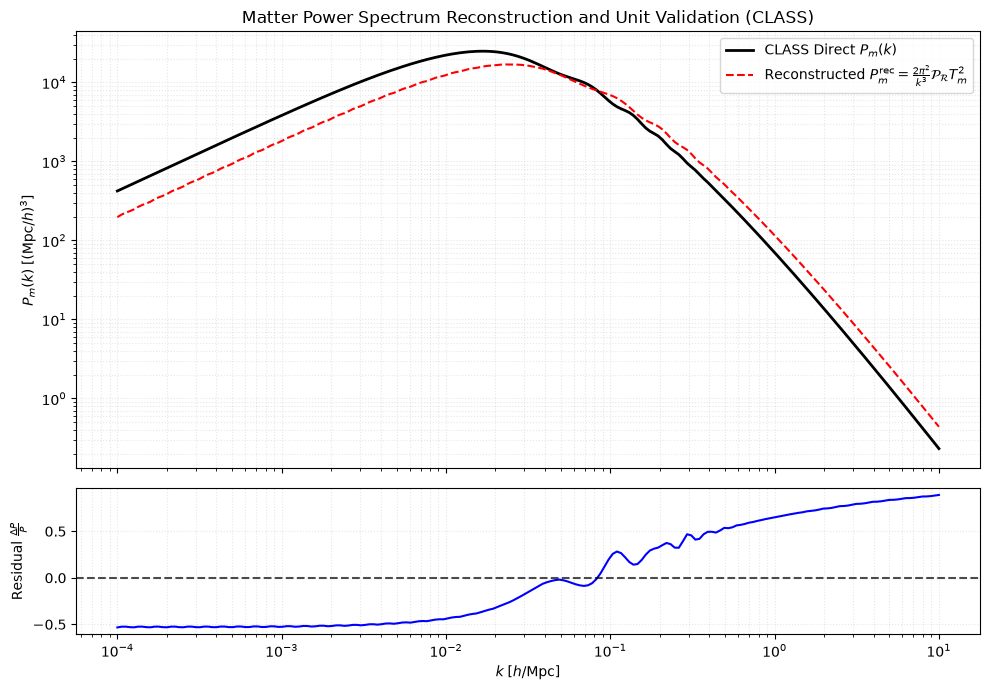

In [31]:
fig, axes = plt.subplots( 2, 1, figsize = ( 10, 7 ), sharex = True, gridspec_kw = {'height_ratios': [ 3, 1 ]} )

axes[0].plot( k_h, pk_class_h, 'k-',  lw =2,    label = r'CLASS Direct $P_m(k)$' )
axes[0].plot( k_h, pk_rec_h,   'r--', lw = 1.5, label = r'Reconstructed $P_m^{\mathrm{rec}} = \frac{2\pi^2}{k^3} \mathcal{P}_{\mathcal{R}} T_m^2$' )

axes[0].set_xscale( 'log' )
axes[0].set_yscale( 'log' )
axes[0].set_ylabel( r'$P_m(k) \; [(\mathrm{Mpc}/h)^3]$' )
axes[0].set_title( 'Matter Power Spectrum Reconstruction and Unit Validation (CLASS)')
axes[0].grid( True, which = "both", ls = ":", alpha = 0.3 )
axes[0].legend()

axes[1].plot( k_h, residual, 'b-' )
axes[1].axhline( 0, color = 'k', linestyle = '--', alpha = 0.7 )
axes[1].set_xscale( 'log')
axes[1].set_xlabel( r'$k \; [h/\mathrm{Mpc}]$' )
axes[1].set_ylabel( r'Residual $\frac{\Delta P}{P}$' )
axes[1].grid( True, which = "both", ls = ":", alpha = 0.3 ) 

plt.tight_layout()
plt.savefig( f"{output_base}_Pm_reconstruction.png", dpi = 300, bbox_inches = "tight" ) 
plt.show()

cosmo.struct_cleanup()
cosmo.empty()

### Precision and Convergence Test

In [32]:
cosmo_def = Class()
cosmo_def.set(
    {'h': h, 'omega_b': Omega_b * ( h ** 2 ), 'omega_cdm': Omega_cdm * ( h ** 2 ), 'A_s': A_s, 'n_s': n_s, 'k_pivot': k_pivot,
    'output': 'mPk', 'z_pk': z_output, 'non linear': 'none','P_k_max_h/Mpc': k_max * 1.5
    })

cosmo_def.compute()


cosmo_prec = Class()
cosmo_prec.set({ 
    'h': h, 'omega_b': Omega_b * ( h ** 2 ), 'omega_cdm': Omega_cdm * ( h ** 2 ), 'A_s': A_s, 'n_s': n_s, 'k_pivot': k_pivot,
    'output': 'mPk', 'z_pk': z_output, 'non linear': 'none', 'k_per_decade_for_pk': boltzmann_prec_opts.get( 'k_per_decade_for_pk', 100 ), 
    'l_max_g': 50, 'l_max_ur': 50, 'tol_perturbations_integration': boltzmann_prec_opts.get( 'rtol', 1e-8 ), 'P_k_max_h/Mpc': k_max * 1.5
    })

cosmo_prec.compute()


In [33]:
pk_def  = np.array([ cosmo_def.pk_lin( k_val, z_output ) for k_val in k_mpc ])
pk_prec = np.array([ cosmo_prec.pk_lin( k_val, z_output ) for k_val in k_mpc ])

precision_ratio = pk_prec / pk_def

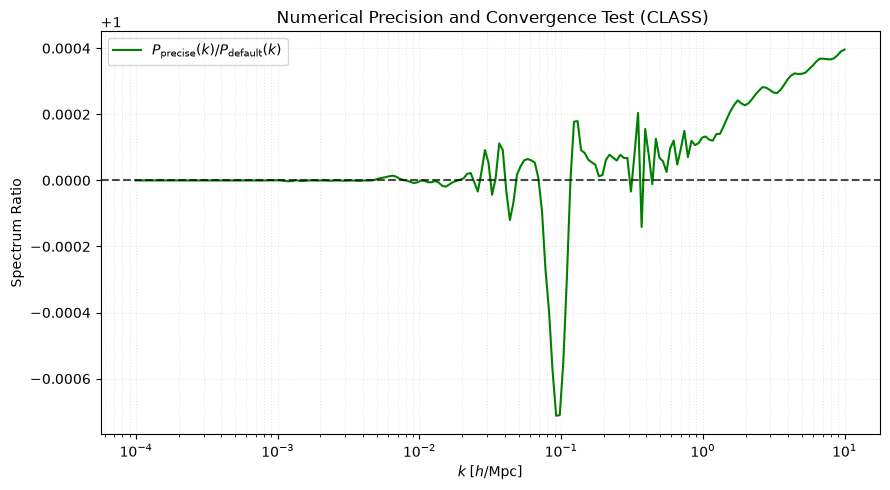

In [34]:
plt.figure(figsize=(9, 5))

plt.plot( k_h, precision_ratio, 'g-', label = r'$P_{\mathrm{precise}}(k) / P_{\mathrm{default}}(k)$' )
plt.axhline( 1.0, color = 'k', linestyle = '--', alpha = 0.7 )

plt.xscale( 'log' )
plt.xlabel( r'$k \; [h/\mathrm{Mpc}]$' )
plt.ylabel( r'Spectrum Ratio' )
plt.title(' Numerical Precision and Convergence Test (CLASS)' )

plt.grid( True, which = "both", ls = ":", alpha = 0.3 )
plt.legend()


plt.tight_layout()
plt.savefig( f"{output_base}_precision_test.png", dpi = 300, bbox_inches = "tight" )
plt.show()


cosmo_def.struct_cleanup()
cosmo_def.empty()

cosmo_prec.struct_cleanup()
cosmo_prec.empty()

### Independent Solver Comparison (CLASS vs CAMB)

In [35]:
cosmo_c = Class()
cosmo_c.set({
    'h': h, 'omega_b': Omega_b * ( h ** 2 ), 'omega_cdm': Omega_cdm * ( h ** 2 ), 'A_s': A_s, 'n_s': n_s, 'k_pivot': k_pivot,
    'output': 'mPk', 'z_pk': z_output, 'non linear': 'none','P_k_max_h/Mpc': k_max
    })

cosmo_c.compute()

pk_class_compare = np.array( [ cosmo_c.pk_lin( k_val, z_output ) * ( h ** 3 ) for k_val in k_mpc ] )

In [36]:
pars = camb.CAMBparams()
pars.set_cosmology(
    H0 = 100.0 * h, ombh2 = Omega_b * ( h ** 2 ), omch2 = Omega_cdm * ( h ** 2 ), omk = 0.0, standard_neutrino_neff = 3.046
    )
pars.InitPower.set_params(
    As = A_s, ns = n_s, pivot_scalar = k_pivot
    )
pars.set_matter_power(
    redshifts = [ z_output ] , kmax = k_max
    )

pars.NonLinear = camb.model.NonLinear_none

results                  = camb.get_results( pars )
kh_camb, z_camb, pk_camb = results.get_matter_power_spectrum(
    minkh = k_min, maxkh = k_max, npoints = k_num_points
)

pk_camb_interp = np.interp(k_h, kh_camb, pk_camb[0])

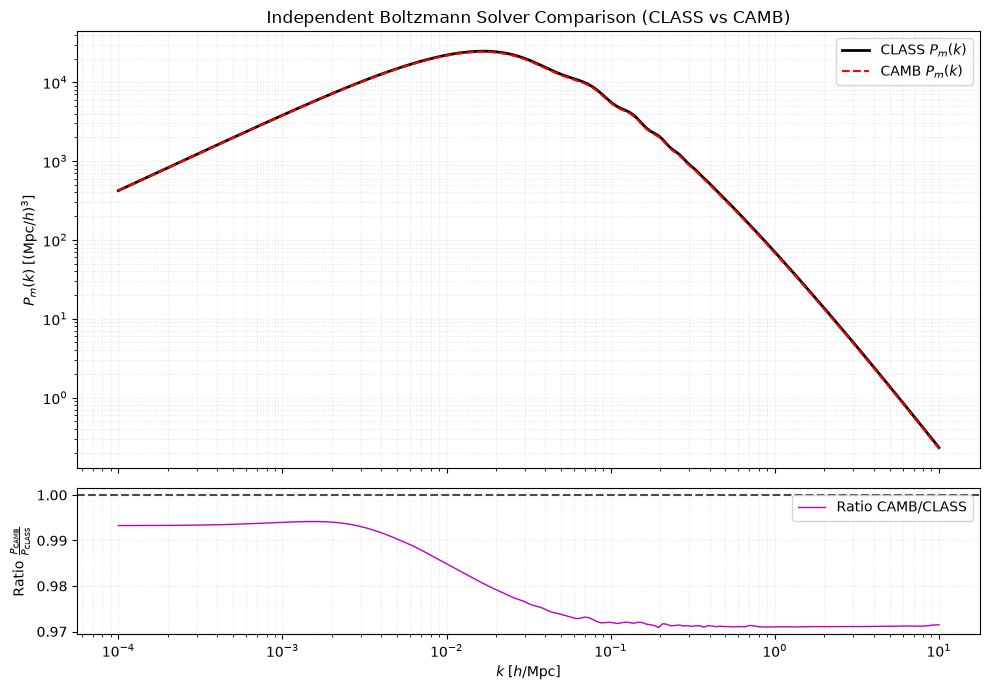

In [37]:
ratio_camb_class = pk_camb_interp / pk_class_compare

fig, axes = plt.subplots( 2, 1, figsize = ( 10, 7 ), sharex = True, gridspec_kw = {'height_ratios': [ 3, 1 ]} )

axes[0].plot( k_h, pk_class_compare, 'k-',  lw = 2,   label = r'CLASS $P_m(k)$' )
axes[0].plot( k_h, pk_camb_interp,   'r--', lw = 1.5, label = r'CAMB $P_m(k)$' )
axes[0].set_xscale( 'log' )
axes[0].set_yscale( 'log' )
axes[0].set_ylabel( r'$P_m(k) \; [(\mathrm{Mpc}/h)^3]$' )
axes[0].set_title( 'Independent Boltzmann Solver Comparison (CLASS vs CAMB)' )
axes[0].grid( True, which = "both", ls = ":", alpha = 0.3)
axes[0].legend( )

axes[1].plot( k_h, ratio_camb_class, 'm-', lw = 1.0, label = r'Ratio $\mathrm{CAMB} / \mathrm{CLASS}$' )
axes[1].axhline( 1.0, color = 'k', linestyle = '--', alpha = 0.7 )
axes[1].set_xscale( 'log' )
axes[1].set_xlabel( r'$k \; [h/\mathrm{Mpc}]$' )
axes[1].set_ylabel( r'Ratio $\frac{P_{\mathrm{CAMB}}}{P_{\mathrm{CLASS}}}$' )
axes[1].grid( True, which = "both", ls = ":", alpha = 0.3 )
axes[1].legend()

plt.tight_layout()
plt.savefig( f"{output_base}_class_vs_camb.png", dpi = 300, bbox_inches = "tight" )
plt.show()

cosmo_c.struct_cleanup()
cosmo_c.empty()

### Supplementary Check A

In [38]:
k_val   = 1.0 
tau_max = 20.0

tau_eval = np.linspace( 1e-3, tau_max, 400 )
exact_j0 = spherical_jn( 0, k_val * tau_eval )

tau_l4, y_l4 = validator.solve_free_streaming_hierarchy(
    k = k_val, l_max = 4, tau_max = tau_max, closure_type = 'zero'
)

tau_l15, y_l15 = validator.solve_free_streaming_hierarchy(
    k = k_val, l_max = 15, tau_max = tau_max, closure_type = 'zero'
)

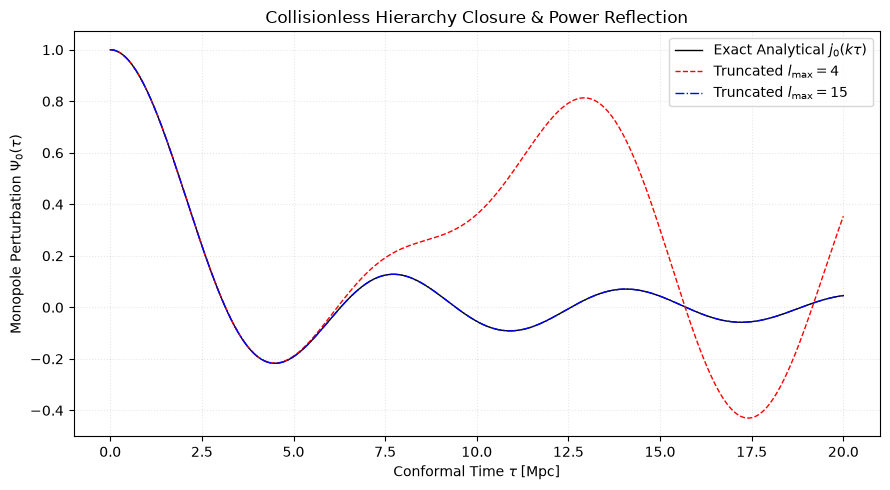

In [39]:
plt.figure( figsize = ( 9, 5 ) )

plt.plot( tau_eval, exact_j0,   'k-', lw = 1.0, label = r'Exact Analytical $j_0(k\tau)$' )
plt.plot( tau_l4, y_l4[ 0 ],   'r--', lw = 1.0, label = r'Truncated $l_{\mathrm{max}}=4$' )
plt.plot( tau_l15, y_l15[ 0 ], 'b-.', lw = 1.0, label = r'Truncated $l_{\mathrm{max}}=15$' )

plt.xlabel( r'Conformal Time $\tau \; [\mathrm{Mpc}]$' )
plt.ylabel( r'Monopole Perturbation $\Psi_0(\tau)$' )
plt.title( 'Collisionless Hierarchy Closure & Power Reflection' )

plt.grid( True, which = 'both', ls=':', alpha = 0.3 )
plt.legend()

plt.tight_layout()

plt.savefig(f'{output_base}_hierarchy_closure.png', dpi = 300, bbox_inches = 'tight')
plt.show()

### Supplementary Check B 

In [40]:
y_vals, phi_vals = validator.solve_superhorizon_potencial( y_init = y_i, y_final = y_f )

phi_i_val = phi_vals[ 0 ]
phi_f_val = phi_vals[ - 1 ]
ratio_val = phi_f_val / phi_i_val

print("=" * 65)
print("Supplementary Check B Validation:")
print(f"Phi Initial (y = {float(y_i):.1e}): {phi_i_val:.6f} | Expected: -0.666662")
print(f"Phi Final   (y = {float(y_f):.1e}): {phi_f_val:.6f} | Expected: -0.600000")
print(f"Ratio Phi_m / Phi_r:        {ratio_val:.6f} | Expected:  0.900000")
print("=" * 65)


Supplementary Check B Validation:
Phi Initial (y = 1.0e-04): -0.666662 | Expected: -0.666662
Phi Final   (y = 1.0e+03): -0.600133 | Expected: -0.600000
Ratio Phi_m / Phi_r:        0.900205 | Expected:  0.900000


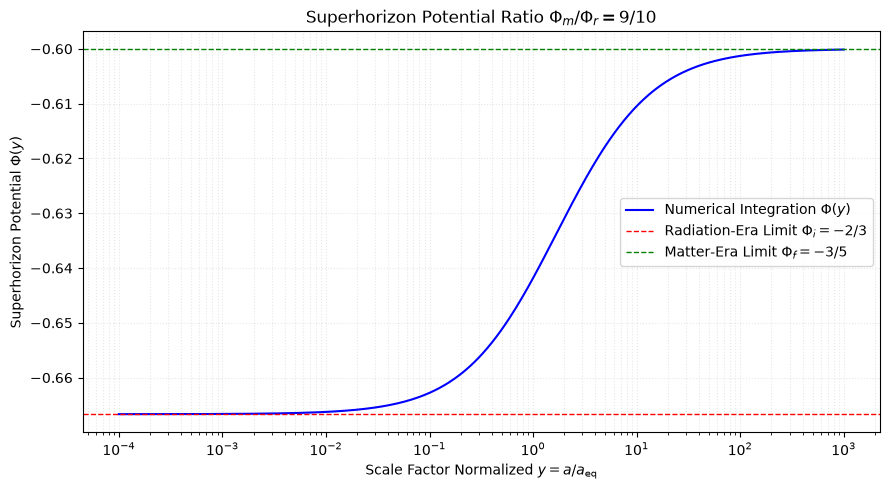

In [41]:
plt.figure( figsize = ( 9, 5 ) )

plt.semilogx( y_vals, phi_vals, 'b-', label = r'Numerical Integration $\Phi(y)$' )
plt.axhline( -2.0/3.0, color = 'r', linestyle = '--', lw = 1.0, label = r'Radiation-Era Limit $\Phi_i = -2/3$' )
plt.axhline( -3.0/5.0, color = 'g', linestyle = '--', lw = 1.0, label = r'Matter-Era Limit $\Phi_f = -3/5$' )

plt.xlabel( r'Scale Factor Normalized $y = a / a_{\mathrm{eq}}$' )
plt.ylabel( r'Superhorizon Potential $\Phi(y)$' )

plt.title( r'Superhorizon Potential Ratio $\Phi_m / \Phi_r = 9/10$' )
plt.grid( True, which = "both", ls = ":", alpha = 0.3 )
plt.legend()

plt.tight_layout()
plt.savefig(f"{output_base}_superhorizon_potential.png", dpi = 300, bbox_inches = "tight" )
plt.show()